# 03 · Preparación y esquema de validación

| | |
|---|---|
| **Entrega** | PSet 3, sección 3 de `CD_PSet_3.pdf` (Preparación y esquema de validación) |
| **Autor** | Allan Paul Gómez Ehmig (00351916) |
| **Código** | todo vive en `src/pipeline.py`; este notebook solo lo importa (como `preparacion_taxis.py` en los laboratorios 10–12) |
| **Datos** | solo **entrenamiento**; el hold-out se cuenta pero no se usa |

### Qué pide el PDF y dónde está

| Requisito | Dónde |
|---|---|
| Imputación, codificación y escalado dentro de un `Pipeline` y un `ColumnTransformer` ajustados solo con entrenamiento | sección 2 y `preparacion()` / `crear_pipeline()` |
| La preparación vive en `src/pipeline.py` y los notebooks la importan | celda de carga (no se copia código) |
| Dividir los datos una sola vez: entrenamiento y prueba (hold-out) | sección 1 y `dividir()` |
| Elegir el esquema de CV que corresponde a los datos y justificarlo | sección 3 y `pliegues()` (**TimeSeriesSplit**) |
| Métrica técnica igual para todos los modelos | sección 4 y `validar()` (MAE) |
| Métrica de negocio que refleja el error más costoso | sección 4 y `src/negocio.py` |
| Cambiar de métrica si otra es mejor, y justificarlo | sección 5 |

Cómo correrlo: `uv run --group modelos jupyter execute --inplace notebooks/03_preparacion_validacion.ipynb`
(2–4 min).

In [1]:
# Todo se importa de src/: el notebook no define preparacion, division ni pliegues.
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().resolve()
if RAIZ.name == 'notebooks':
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
from src.datos import cargar
from src.pipeline import (preparar, dividir, preparacion, crear_pipeline, pliegues, validar, predecir_pliegues,
                          mes_objetivo, FEATURES, NUMERICAS, CATEGORICAS, YA_LISTAS, TARGET, METRICA_TECNICA)
from src.evaluacion import errores, ic_por_mes, resumen_ic
from src.negocio import metrica_negocio, portafolios_aleatorios, sharpe_anual, drawdown_maximo, REGLA

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.3})
FIG = RAIZ / 'docs/figuras'; FIG.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    fig.savefig(FIG / f'validacion_{nombre}.png', dpi=130, bbox_inches='tight')

obt, meta = cargar()
datos = preparar(obt)
train, holdout = dividir(datos)          # la UNICA division del proyecto
train = train.reset_index(drop=True)
print(json.dumps({'sha256': meta['sha256'][:16], 'numericas': len(NUMERICAS), 'categoricas': CATEGORICAS,
                  'ya_listas': YA_LISTAS, 'columnas_X': len(FEATURES)}, indent=1))

{
 "sha256": "c356891723976bce",
 "numericas": 34,
 "categoricas": [
  "mes_calendario_obj"
 ],
 "ya_listas": [],
 "columnas_X": 35
}


## 1. Una sola división: entrenamiento y hold-out

`dividir()` corta por la **fecha del objetivo**, nunca al azar. Cada fila del mes *t* predice el retorno de
*t+1*, así que la fila de diciembre de 2023 tiene su objetivo en enero de 2024 y va al hold-out
(`objetivo_cruza_corte`). Si se cortara por el mes de las features, el retorno de enero de 2024 se usaría para
entrenar.

| Conjunto | Objetivo | Uso |
|---|---|---|
| Entrenamiento | hasta 2023-12 | validación cruzada, comparación de modelos y tuning |
| Prueba (hold-out) | desde 2024-01 | una sola vez, al final, con el ganador y el segundo mejor |

In [2]:
# Tamano de cada conjunto y comprobacion de que no se tocan.
def resumen(d):
    mo = mes_objetivo(d)
    return {'filas': len(d), 'acciones': d.accion_key.nunique(), 'meses': mo.nunique(),
            'primer_objetivo': str(mo.min()), 'ultimo_objetivo': str(mo.max())}
display(pd.DataFrame({'entrenamiento': resumen(train), 'hold-out': resumen(holdout)}).T)

mo_tr, mo_ho = mes_objetivo(train), mes_objetivo(holdout)
assert mo_tr.max() == pd.Period('2023-12', freq='M') and mo_ho.min() == pd.Period('2024-01', freq='M')
assert not set(mo_tr) & set(mo_ho)
cruza = holdout[holdout.anio_mes == 202312]
print(f'Sin meses compartidos. Las {len(cruza)} filas de 2023-12 (objetivo 2024-01) estan en el hold-out.')
if 'objetivo_cruza_corte' in holdout:
    print('objetivo_cruza_corte en esas filas:', holdout.loc[holdout.anio_mes == 202312, 'objetivo_cruza_corte'].astype(bool).all())

,filas,acciones,meses,primer_objetivo,ultimo_objetivo
entrenamiento,46851,380,158,2010-11,2023-12
hold-out,11326,350,34,2024-01,2026-10


Sin meses compartidos. Las 332 filas de 2023-12 (objetivo 2024-01) estan en el hold-out.
objetivo_cruza_corte en esas filas: True


## 2. Preparación dentro de un Pipeline (`src/pipeline.py`)

Tiene la misma forma que la plantilla de los laboratorios (`semana-09-sesion-02/plantilla-pipeline`) y que
`preparacion_taxis.py` (semanas 10–12):

```python
NUMERICAS   = 33 de la OBT + dispersion_mes      -> imputar mediana + StandardScaler
CATEGORICAS = ['mes_calendario_obj']              -> imputar moda + OneHotEncoder (12 categorías fijas, enero de referencia)
YA_LISTAS   = []
preparacion()          -> ColumnTransformer de esos tres grupos
crear_pipeline(modelo) -> Pipeline([("preparar", preparacion()), ("modelo", modelo)])
```

El Pipeline completo se ajusta con `fit` sobre el entrenamiento de cada pliegue, así que las medianas, las medias
y las desviaciones nunca ven la validación ni el hold-out. `src/modelos/tabulares.py` (tuning) reutiliza el mismo
`preparacion()`: solo agrega el rango transversal antes y `SelectKBest` después.

In [3]:
# El Pipeline y la prueba de que se ajusta solo con el entrenamiento del pliegue.
from sklearn.linear_model import Ridge
cv = pliegues(train)
it, iv = cv[0]
p = crear_pipeline(Ridge(alpha=10.0)).fit(train[FEATURES].iloc[it], train[TARGET].iloc[it])
print(p)
prep = p.named_steps['preparar']
num = prep.named_transformers_['numericas']
ent = train[NUMERICAS].iloc[it]
assert np.allclose(num.named_steps['imputar'].statistics_, ent.median(), equal_nan=True)
assert np.allclose(num.named_steps['escalar'].mean_, ent.fillna(ent.median()).mean())
val = train[NUMERICAS].iloc[iv]
print(f'Medianas y medias = las del entrenamiento del pliegue 1 ({len(it)} filas). '
      f'Con la validacion serian otras: mediana de vol_63d {ent.vol_63d.median():.4f} (ent.) frente a {val.vol_63d.median():.4f} (val.).')
cod = prep.named_transformers_['categoricas'].named_steps['codificar']
print('One-hot del mes:', cod.categories_[0].tolist(), '| referencia (columna eliminada):', cod.categories_[0][cod.drop_idx_[0]])
print(f'X tiene {len(FEATURES)} columnas; tras preparar quedan {len(prep.get_feature_names_out())}.')

Pipeline(steps=[('preparar',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(keep_empty_features=True,
                                                                                 strategy='median')),
                                                                  ('escalar',
                                                                   StandardScaler())]),
                                                  ['ret_log_mes', 'ret_log_21d',
                                                   'ret_log_252d',
                                                   'momentum_12_1', 'vol_21d',
                                                   'vol_63d',
                                                   'vol_apertura_21d',
                                                   'intradia_prom_21d',
                       

## 3. Esquema de validación cruzada: temporal (`TimeSeriesSplit`)

**Elección: `TimeSeriesSplit`**, aplicado sobre los **meses** y no sobre las filas: `pliegues()` en `src/pipeline.py`.

```python
TimeSeriesSplit(n_splits=7, test_size=12, gap=1).split(meses)   # meses únicos del objetivo, en orden
```

- **7 pliegues.** Cada uno valida 12 meses completos, los años 2017 a 2023 (84 meses fuera de muestra), y entrena
  con **todos** los meses anteriores (ventana expansiva, desde 2010-11).
- **`gap=1`.** Deja un mes sin usar entre entrenamiento y validación: el objetivo del último mes de entrenamiento
  (*t+1*) se conoce un mes después del cierre, el mismo mes en que empezaría la validación.
- **Sobre meses, no filas.** Todas las acciones de un mes caen del mismo lado. Un `TimeSeriesSplit` sobre las filas
  partiría un mes entre entrenamiento y validación.

**Por qué no los otros:**

| Esquema | Por qué no sirve aquí |
|---|---|
| Aleatorio (`KFold` / `train_test_split`) | Entrena con meses posteriores a los que valida (usa el futuro) y pone la misma acción y el mismo mes en los dos lados. El mes explica el 34,5 % de la varianza (EDA): el modelo "ve" el choque del mes que debe predecir |
| Por grupo (`GroupKFold` por acción) | Separa acciones, pero cada pliegue mezcla todos los años: entrena con 2023 para validar 2012, y las acciones de validación comparten el choque del mes con las de entrenamiento. El riesgo del proyecto no son acciones nuevas, sino meses nuevos |
| Estratificado (`StratifiedKFold`) | Es para clasificación (mantiene la proporción de clases); aquí el objetivo es continuo y además tiene el mismo problema del aleatorio |
| **Temporal (`TimeSeriesSplit`)** | **Reproduce el uso real:** cada mes se entrena con el pasado y se predice el mes siguiente |

,entrena_objetivos,filas_ent,valida_objetivos,filas_val,meses_de_separacion,meses_compartidos
pliegue,,,,,,
1,2010-11 .. 2016-11,19855,2017-01 .. 2017-12,3619,1,0
2,2010-11 .. 2017-11,23465,2018-01 .. 2018-12,3708,1,0
3,2010-11 .. 2018-11,27169,2019-01 .. 2019-12,3778,1,0
4,2010-11 .. 2019-11,30939,2020-01 .. 2020-12,3864,1,0
5,2010-11 .. 2020-11,34799,2021-01 .. 2021-12,3881,1,0
6,2010-11 .. 2021-11,38681,2022-01 .. 2022-12,3908,1,0
7,2010-11 .. 2022-11,42583,2023-01 .. 2023-12,3938,1,0


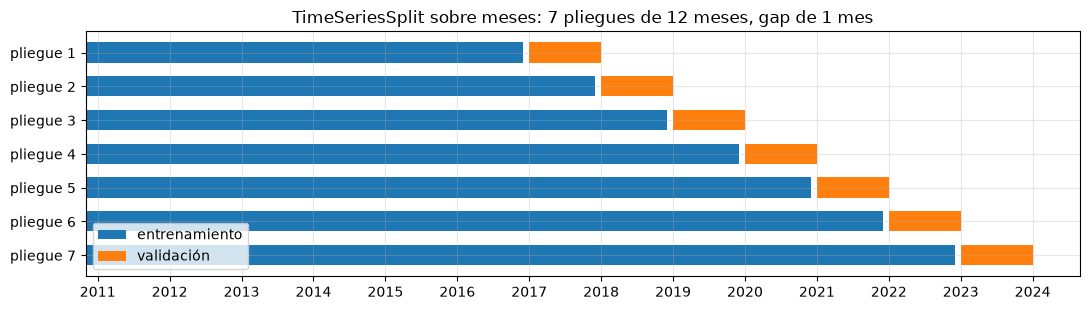

In [4]:
# Los 7 pliegues: rango de meses, filas y separacion.
filas = []
mo = mes_objetivo(train)
for k, (it, iv) in enumerate(cv):
    filas.append({'pliegue': k + 1, 'entrena_objetivos': f'{mo[it].min()} .. {mo[it].max()}', 'filas_ent': len(it),
                  'valida_objetivos': f'{mo[iv].min()} .. {mo[iv].max()}', 'filas_val': len(iv),
                  'meses_de_separacion': (mo[iv].min() - mo[it].max()).n - 1,
                  'meses_compartidos': len(set(mo[it].asi8) & set(mo[iv].asi8))})
tabla_pliegues = pd.DataFrame(filas).set_index('pliegue')
display(tabla_pliegues)
tabla_pliegues.to_csv(RAIZ / 'docs/pliegues_cv.csv')

fig, ax = plt.subplots(figsize=(11, 3.2))
for k, (it, iv) in enumerate(cv):
    ax.barh(k, (mo[it].max() - mo[it].min()).n + 1, left=mo[it].min().ordinal, color='tab:blue', height=0.6,
            label='entrenamiento' if k == 0 else None)
    ax.barh(k, 12, left=mo[iv].min().ordinal, color='tab:orange', height=0.6, label='validación' if k == 0 else None)
anios = pd.period_range('2011-01', '2024-01', freq='12M')
ax.set_xticks([a.ordinal for a in anios], [a.year for a in anios]); ax.set_yticks(range(len(cv)), [f'pliegue {k+1}' for k in range(len(cv))])
ax.invert_yaxis(); ax.legend(loc='lower left'); ax.set_title('TimeSeriesSplit sobre meses: 7 pliegues de 12 meses, gap de 1 mes')
plt.tight_layout(); guardar(fig, 'pliegues'); plt.show()

### Fechas de corte de cada pliegue

Cada fila del mes *t* (features al cierre de *t*) predice el retorno de *t+1*. Por eso hay dos fechas para cada
límite:
- **mes del objetivo**: lo que separa `TimeSeriesSplit`;
- **cierre de las features**: la fecha en que se toma la decisión.

El mes de separación (`gap`) no se usa en ninguno de los dos lados. La fila del hold-out se agrega como referencia.

In [5]:
# Fechas de corte: ultimo objetivo de entrenamiento, mes excluido (gap) y rango de validacion, en meses y en fechas.
def cierre(periodo):
    return periodo.end_time.date().isoformat()          # ultimo dia calendario del mes
cortes = []
for k, (it, iv) in enumerate(cv):
    ult_ent, ini_val, fin_val = mo[it].max(), mo[iv].min(), mo[iv].max()
    cortes.append({'pliegue': str(k + 1),
                   'entrena: objetivos hasta': str(ult_ent),
                   'entrena: ultimo cierre de features': cierre(ult_ent - 1),
                   'gap (excluido): objetivo': str(ult_ent + 1),
                   'valida: objetivos': f'{ini_val} .. {fin_val}',
                   'valida: cierres de decision': f'{cierre(ini_val - 1)} .. {cierre(fin_val - 1)}',
                   'fecha de corte (fin del ultimo objetivo de entrenamiento)': cierre(ult_ent)})
mo_ho = mes_objetivo(holdout)
cortes.append({'pliegue': 'hold-out', 'entrena: objetivos hasta': str(mo.max()), 'entrena: ultimo cierre de features': cierre(mo.max() - 1),
               'gap (excluido): objetivo': '-', 'valida: objetivos': f'{mo_ho.min()} .. {mo_ho.max()}',
               'valida: cierres de decision': f'{cierre(mo_ho.min() - 1)} .. {cierre(mo_ho.max() - 1)}',
               'fecha de corte (fin del ultimo objetivo de entrenamiento)': cierre(mo.max())})
cortes = pd.DataFrame(cortes).set_index('pliegue')
cortes.to_csv(RAIZ / 'docs/cortes_cv.csv')
display(cortes)

,entrena: objetivos hasta,entrena: ultimo cierre de features,gap (excluido): objetivo,valida: objetivos,valida: cierres de decision,fecha de corte (fin del ultimo objetivo de entrenamiento)
pliegue,,,,,,
1,2016-11,2016-10-31,2016-12,2017-01 .. 2017-12,2016-12-31 .. 2017-11-30,2016-11-30
2,2017-11,2017-10-31,2017-12,2018-01 .. 2018-12,2017-12-31 .. 2018-11-30,2017-11-30
3,2018-11,2018-10-31,2018-12,2019-01 .. 2019-12,2018-12-31 .. 2019-11-30,2018-11-30
4,2019-11,2019-10-31,2019-12,2020-01 .. 2020-12,2019-12-31 .. 2020-11-30,2019-11-30
5,2020-11,2020-10-31,2020-12,2021-01 .. 2021-12,2020-12-31 .. 2021-11-30,2020-11-30
6,2021-11,2021-10-31,2021-12,2022-01 .. 2022-12,2021-12-31 .. 2022-11-30,2021-11-30
7,2022-11,2022-10-31,2022-12,2023-01 .. 2023-12,2022-12-31 .. 2023-11-30,2022-11-30
hold-out,2023-12,2023-11-30,-,2024-01 .. 2026-10,2023-12-31 .. 2026-09-30,2023-12-31


**Cómo leer una fila.** En el pliegue 1:
- el modelo se entrena con objetivos hasta 2016-11, es decir, con features hasta el cierre del 2016-10-31, porque
  el retorno de noviembre se conoce al cierre de noviembre;
- el objetivo 2016-12 (features del cierre 2016-11-30) queda fuera como separación;
- valida las 12 decisiones tomadas entre los cierres 2016-12-31 y 2017-11-30, que predicen enero a diciembre de 2017.

Las fechas son el fin de mes calendario; la OBT usa el último día hábil de cada mes. En el hold-out, el modelo final
se entrena con todo hasta el objetivo 2023-12 y se evalúa una sola vez en 2024-01 en adelante.

### 3.1 Comparación de esquemas (como el laboratorio 11-2)

El mismo modelo (LightGBM pequeño con pérdida L1) y el mismo Pipeline se evalúan con cada esquema. Si un esquema
deja pasar información del futuro o del mismo mes, su MAE sale **más optimista** que el temporal. Ese optimismo no
se repetiría al usar el modelo.

In [6]:
# MAE con cada esquema: temporal (oficial), TimeSeriesSplit sobre filas, aleatorio y por grupo (accion).
from sklearn.model_selection import KFold, GroupKFold, TimeSeriesSplit
from lightgbm import LGBMRegressor
modelo = LGBMRegressor(n_estimators=200, learning_rate=0.03, num_leaves=15, min_child_samples=200, subsample=0.8,
                       subsample_freq=1, colsample_bytree=0.8, objective='l1', random_state=42, verbose=-1)
orden = train.sort_values(['anio_mes', 'accion_key']).index.to_numpy()   # train ya esta en orden de mes
esquemas = {
    'Temporal: TimeSeriesSplit sobre meses (oficial)': cv,
    'TimeSeriesSplit sobre filas (sin agrupar el mes)': list(TimeSeriesSplit(n_splits=7, test_size=len(train) // 13).split(train)),
    'Aleatorio: KFold(5, shuffle, 42)': list(KFold(5, shuffle=True, random_state=42).split(train)),
    'Por grupo: GroupKFold(5) por accion': list(GroupKFold(5).split(train, groups=train.accion_key)),
}
mes_int = np.asarray(mo.asi8)        # meses como enteros: np.isin con objetos Period es muy lento
comparacion = []
for nombre, esquema in esquemas.items():
    r = validar(modelo, train, cv=esquema)
    comparte_mes = np.mean([np.isin(mes_int[iv], mes_int[it]).mean() for it, iv in esquema])
    futuro = np.mean([(mes_int[it].max() > mes_int[iv].min()) for it, iv in esquema])
    comparacion.append({'esquema': nombre, 'mae_cv_media': r['mae_cv_media'], 'mae_cv_std': r['mae_cv_std'],
                        'filas_val_con_su_mes_en_ent': comparte_mes, 'pliegues_que_entrenan_con_futuro': futuro})
comparacion = pd.DataFrame(comparacion).set_index('esquema')
display(comparacion.style.format({'mae_cv_media': '{:.5f}', 'mae_cv_std': '{:.5f}',
                                  'filas_val_con_su_mes_en_ent': '{:.0%}', 'pliegues_que_entrenan_con_futuro': '{:.0%}'}))
comparacion.to_csv(RAIZ / 'docs/comparacion_esquemas_cv.csv')
oficial = comparacion.mae_cv_media.iloc[0]
for nombre, fila in comparacion.iloc[1:].iterrows():
    print(f'{nombre}: MAE {fila.mae_cv_media:.5f}, {100 * (fila.mae_cv_media / oficial - 1):+.1f} % frente al temporal')

,mae_cv_media,mae_cv_std,filas_val_con_su_mes_en_ent,pliegues_que_entrenan_con_futuro
esquema,,,,
Temporal: TimeSeriesSplit sobre meses (oficial),0.06514,0.01770,0%,0%
TimeSeriesSplit sobre filas (sin agrupar el mes),0.06698,0.01386,3%,0%
"Aleatorio: KFold(5, shuffle, 42)",0.04758,0.00044,100%,100%
Por grupo: GroupKFold(5) por accion,0.04752,0.00223,100%,100%


TimeSeriesSplit sobre filas (sin agrupar el mes): MAE 0.06698, +2.8 % frente al temporal
Aleatorio: KFold(5, shuffle, 42): MAE 0.04758, -27.0 % frente al temporal
Por grupo: GroupKFold(5) por accion: MAE 0.04752, -27.1 % frente al temporal


**Lectura.** El aleatorio y el de grupo entrenan con el futuro y con el mismo mes que validan. Por eso su MAE sale
**más bajo**: es una estimación optimista que no se repetiría en producción, donde siempre se predice un mes que
el modelo no vio. El `TimeSeriesSplit` sobre filas no usa el futuro, pero corta meses por la mitad. El esquema
oficial es el único que reproduce la decisión real.

## 4. Métricas

### 4.1 Métrica técnica: MAE, y las demás métricas usuales

**El MAE decide**, y es el mismo para todos los modelos (decisión W3, `docs/diseno_experimental.md`). Se eligió
porque el objetivo tiene colas gruesas (curtosis 9,6, EDA): el RMSE premiaría acertar pocos meses extremos.

`validar()` calcula, además, todas las métricas usuales de regresión (`PUNTAJES` en `src/pipeline.py`). Se
registran siempre, pero hoy **no se usan para decidir**. Para *y* = retorno real, *ŷ* = predicción y *e* = *ŷ* − *y*:

| Métrica | Definición | Lectura |
|---|---|---|
| **MAE** (decide) | promedio de \|e\| | error típico, en unidades de retorno log |
| RMSE | √ promedio de e² | castiga más los errores grandes |
| MSE | promedio de e² | el RMSE al cuadrado |
| MedAE | mediana de \|e\| | error típico sin las colas |
| Error máximo | máx \|e\| del pliegue | el peor caso |
| R² | 1 − Σe² / Σ(y − ȳ)² | contra predecir la media **del pliegue de validación**, que no se conoce de antemano: suele ser < 0 en retornos |
| Varianza explicada | 1 − Var(e) / Var(y) | como el R², pero sin castigar un sesgo constante |
| R² contra RW | 1 − Σe² / Σy² | > 0 = mejor que predecir retorno 0 (random walk) |
| Acierto direccional | % de filas con signo(ŷ) = signo(y) | ignora las predicciones = 0 |

No se usa el **MAPE**: el retorno vale casi 0 muchos meses y el error porcentual se vuelve infinito.

Además se reporta siempre el **IC de Spearman por mes** (correlación de rangos entre la predicción y el retorno,
dentro de cada mes). Mide si el modelo **ordena** bien las acciones, que es lo que usa la regla de inversión.
`validar()` es como `evaluar()` del laboratorio 11-2, y la usan también `src/experimentos.py` (MLflow) y el
tuning.

In [7]:
# Metrica tecnica para lineas base y dos modelos, con los mismos pliegues.
from sklearn.dummy import DummyRegressor
candidatos = {'B1 media (Dummy)': DummyRegressor(), 'B2 random walk (retorno 0)': DummyRegressor(strategy='constant', constant=0.0),
              'Ridge (alpha 10)': Ridge(alpha=10.0), 'LightGBM (L1)': modelo}
tecnica = pd.DataFrame({n: validar(m, train) for n, m in candidatos.items()}).T
from src.pipeline import PUNTAJES
print('Promedio en los 7 pliegues de validacion (el MAE decide; las demas son informativas):')
display(pd.DataFrame({m: tecnica[f'{m}_cv_media'] for m in PUNTAJES}).astype(float).T.round(4))
print('MAE: desviacion entre pliegues, promedio en entrenamiento y segundos:')
display(tecnica[['mae_cv_media', 'mae_cv_std', 'mae_train_cv', 'segundos']].astype(float).round(5))
display(pd.DataFrame(tecnica.mae_pliegues.tolist(), index=tecnica.index,
                     columns=[f'{mo[iv].min().year}' for _, iv in cv]).round(4))

Promedio en los 7 pliegues de validacion (el MAE decide; las demas son informativas):


,B1 media (Dummy),B2 random walk (retorno 0),Ridge (alpha 10),LightGBM (L1)
mae,0.0641,0.0647,0.0679,0.0651
rmse,0.0868,0.0870,0.0923,0.0893
mse,0.0081,0.0081,0.0094,0.0087
medae,0.0501,0.0509,0.0519,0.0505
max_error,0.6470,0.6418,0.6865,0.6785
r2,-0.0227,-0.0335,-0.1423,-0.0749
varianza_explicada,-0.0000,0.0000,-0.0815,-0.0263
r2_vs_rw,0.0095,0.0000,-0.1083,-0.0423
acierto_direccional,0.5623,NaN,0.5333,0.5400


MAE: desviacion entre pliegues, promedio en entrenamiento y segundos:


,mae_cv_media,mae_cv_std,mae_train_cv,segundos
B1 media (Dummy),0.06410,0.01649,0.05290,0.56072
B2 random walk (retorno 0),0.06474,0.01593,0.05392,0.55157
Ridge (alpha 10),0.06792,0.01979,0.05134,0.57113
LightGBM (L1),0.06514,0.01770,0.04306,6.04438


,2017,2018,2019,2020,2021,2022,2023
B1 media (Dummy),0.0406,0.0572,0.0564,0.0913,0.0590,0.0783,0.0660
B2 random walk (retorno 0),0.0423,0.0565,0.0588,0.0918,0.0604,0.0773,0.0661
Ridge (alpha 10),0.0415,0.0652,0.0566,0.1040,0.0609,0.0807,0.0665
LightGBM (L1),0.0410,0.0602,0.0545,0.0909,0.0602,0.0867,0.0625


### 4.2 Métrica de negocio: el portafolio de la regla del PSet 1

El modelo no se usa para adivinar el retorno exacto, sino para **elegir acciones**. La métrica de negocio mide
cuánto habría ganado el cliente, y con qué caídas, si cada mes hubiera seguido la regla con las predicciones del
modelo. Está en `src/negocio.py` (`backtest`, `metrica_negocio`) y sus parámetros, en `REGLA`.

Todo se expresa en **US$** y en fracciones del capital. "Ponderación" (*w*) es la fracción del capital que va a
cada acción, no una moneda.

**Regla, cada cierre de mes *t*** (parámetros decididos el 18-nov, `REGLA`):
1. **Tope relativo por acción:** se excluye el **20 % más volátil del mes**, es decir, las acciones con `vol_63d`
   por encima del percentil 80 de todas las elegibles de ese mes. Al ser relativo, se adapta a meses tranquilos y a
   crisis como 2020.
2. **Elegir:** de las que quedan, las *n* = 10 con mayor predicción *ŷ*.
3. **Ponderar:** wᵢ = (1 / volᵢ) / Σⱼ (1 / volⱼ), con vol = `vol_63d` anualizada. La acción más volátil recibe
   menos capital. Solo compras, sin apalancamiento: las ponderaciones suman 1.
4. **Tope de portafolio:** la volatilidad estimada del portafolio, σ_p = √(wᵀ Σ w · 252), donde Σ es la covarianza
   de los retornos diarios de los últimos 63 días hábiles (`OBT_ACCION_DIA`), no puede superar **1,35 × σ del
   S&P 500** en esos mismos 63 días. Si la supera, solo se invierte la fracción k = 1,35·σ_S&P / σ_p en acciones y
   el resto queda en efectivo, que gana la tasa libre de riesgo. Ejemplo: con σ_S&P = 15 %, el tope es 20,25 %. Si
   el portafolio elegido tiene σ_p = 27 %, se invierte k = 75 % (75.000 de cada 100.000 US$) y 25.000 US$ quedan en
   efectivo.
5. **Retorno bruto del mes *t+1*:** R_bruto = Σᵢ wᵢ · rᵢ + (1 − Σwᵢ) · rf, con rᵢ el retorno **simple** de *t+1*
   (`ret_pct_mes_siguiente`, porque los retornos simples se suman entre acciones). Una acción que deja de cotizar
   aporta 0.
6. **Rotación (turnover):** Σᵢ |wᵢ nuevo − wᵢ derivado|, donde las ponderaciones derivadas son las del mes anterior
   después de moverse con los precios. Es la fracción del capital que se compra más la que se vende: vale 1 el primer
   mes (comprar todo desde efectivo) y hasta 2 si se cambia todo el portafolio.
7. **Costo: 15 pb por cada US$ operado** (`costo_bps` = 15). 1 pb (punto básico) = 0,01 %, así que se paga 0,15 %,
   es decir, 0,15 US$ por cada 100 US$ comprados o vendidos. Costo del mes = turnover × 0,0015. Ejemplo: con un
   turnover de 1,8 sobre 100.000 US$ se operan 180.000 US$ y el costo es 270 US$ (0,27 % del capital).
8. **Retorno neto:** R_neto = R_bruto − costo.

**Indicadores sobre la serie mensual de R_neto:**
- **Sharpe anual neto** = promedio(R_neto − rf) / desviación(R_neto − rf) × √12, con rf la tasa libre de riesgo
  del mes (^IRX). Es el retorno por unidad de riesgo: 0,5 significa que, por cada 1 % de volatilidad anual, el
  portafolio gana 0,5 % sobre la tasa libre de riesgo. **Es la métrica de negocio que decide.**
- **Drawdown máximo** = mín sobre *t* de (riqueza_t / máximo previo de la riqueza − 1), con riqueza_t = Π(1 +
  R_neto). Es la peor caída desde un máximo. **Mide el error más costoso del proyecto**: en el PSet 1, un portafolio
  más riesgoso de lo que el cliente tolera lo lleva a vender en pánico, en el peor momento. Ejemplo: −0,30 significa
  que 100.000 US$ llegaron a valer 70.000 US$ antes de recuperarse.
- **Retorno anual neto** = (Π(1 + R_neto))^(12/meses) − 1, el crecimiento compuesto por año.
- **Turnover promedio:** cuánto se opera cada mes, que se traduce en costo.

**Contra qué se compara:**
- **B4:** 100 portafolios con la misma regla, pero eligiendo las 10 acciones al azar cada mes. Un modelo útil debe
  superar la mediana de B4.
- **El S&P 500** en los mismos meses, que es la alternativa pasiva del cliente.

El ejemplo siguiente aplica `backtest` a 5 acciones, 2 meses, *n* = 2, el tope relativo y 15 pb, para ver cada paso
con números. El tope de portafolio necesita datos diarios y está probado aparte en `tests/test_diseno.py`.

In [8]:
# Ejemplo pequeno con la misma funcion que usa la metrica: 5 acciones, 2 meses, se eligen 2, tope relativo p80, 15 pb.
from src.negocio import backtest, pesos_mes
ejemplo = pd.DataFrame({
    'anio_mes':              [202001] * 5 + [202002] * 5,
    'accion_key':            ['A', 'B', 'C', 'D', 'E'] * 2,
    'pred':                  [0.03, 0.02, 0.01, -0.01, 0.04,    0.02, -0.01, 0.03, 0.00, 0.05],
    'vol_63d':               [0.20, 0.40, 0.25, 0.30, 0.60,     0.20, 0.40, 0.25, 0.30, 0.60],
    'ret_pct_mes_siguiente': [0.06, -0.03, 0.01, 0.02, 0.15,    -0.04, 0.05, -0.01, -0.01, -0.20],
    'rf_mes_siguiente':      [0.001] * 10})
capital = 100_000
for mes, g in ejemplo.groupby('anio_mes'):
    p80 = g.vol_63d.quantile(0.80)
    w = pesos_mes(g, 'pred', n=2, tope_percentil=0.80)
    print(f'{mes}: percentil 80 de vol = {p80:.2f} -> se excluye E (vol 0,60) aunque tiene la mayor prediccion; '
          f'elige {list(w.index)}; ponderaciones 1/vol = {w.round(4).to_dict()} '
          f'= {(w * capital).round(0).to_dict()} US$ de {capital:,} US$')
serie = backtest(ejemplo, 'pred', n=2, tope_percentil=0.80, costo_bps=15)
display(serie[['bruto', 'turnover', 'neto', 'rf', 'invertido']].round(5))
for mes, f in serie.iterrows():
    print(f'{mes}: bruto {f.bruto:+.2%}; turnover {f.turnover:.4f} -> se operan {f.turnover * capital:,.0f} US$ y el costo es '
          f'{f.turnover * 15 / 1e4 * capital:,.0f} US$ ({f.turnover * 15 / 1e4:.3%}); neto {f.neto:+.2%}')
riqueza = capital * (1 + serie.neto).cumprod()
print(f'Capital al cierre de cada mes: {riqueza.round(0).tolist()} US$. Drawdown maximo = '
      f'{riqueza.iloc[-1]:,.0f} / {riqueza.cummax().iloc[-1]:,.0f} - 1 = {drawdown_maximo(serie):.2%}.')
print('Sin el tope relativo se habria elegido E en los dos meses: +15 % en el primero y -20 % en el segundo. '
      'El tope no busca ganar mas, sino evitar que una accion muy volatil domine las caidas.')

202001: percentil 80 de vol = 0.44 -> se excluye E (vol 0,60) aunque tiene la mayor prediccion; elige ['A', 'B']; ponderaciones 1/vol = {'A': 0.6667, 'B': 0.3333} = {'A': 66667.0, 'B': 33333.0} US$ de 100,000 US$
202002: percentil 80 de vol = 0.44 -> se excluye E (vol 0,60) aunque tiene la mayor prediccion; elige ['C', 'A']; ponderaciones 1/vol = {'C': 0.4444, 'A': 0.5556} = {'C': 44444.0, 'A': 55556.0} US$ de 100,000 US$


,bruto,turnover,neto,rf,invertido
anio_mes,,,,,
202001,0.03000,1.00000,0.0285,0.001,1.0
202002,-0.02667,0.88889,-0.0280,0.001,1.0


202001: bruto +3.00%; turnover 1.0000 -> se operan 100,000 US$ y el costo es 150 US$ (0.150%); neto +2.85%
202002: bruto -2.67%; turnover 0.8889 -> se operan 88,889 US$ y el costo es 133 US$ (0.133%); neto -2.80%
Capital al cierre de cada mes: [102850.0, 99970.0] US$. Drawdown maximo = 99,970 / 102,850 - 1 = -2.80%.
Sin el tope relativo se habria elegido E en los dos meses: +15 % en el primero y -20 % en el segundo. El tope no busca ganar mas, sino evitar que una accion muy volatil domine las caidas.


In [9]:
# Metrica de negocio sobre las predicciones fuera de muestra (84 meses), frente a B4 y al S&P 500.
from src.negocio import RiesgoDiario
riesgo = None
if (RAIZ / 'data/obt_dia.parquet').exists():
    dia, _ = cargar(grano='dia')
    riesgo = RiesgoDiario(dia)
    print(f'Tope de portafolio activo: {len(dia):,} filas diarias de OBT_ACCION_DIA.')
else:
    print('AVISO: falta data/obt_dia.parquet (uv run python -m src.datos --grano dia); '
          'el tope de portafolio NO se aplica en esta corrida, solo el relativo por accion.')
negocio = {}
predicciones = {}
for n in ['Ridge (alpha 10)', 'LightGBM (L1)']:
    predicciones[n] = predecir_pliegues(candidatos[n], train)
    negocio[n] = {**metrica_negocio(predicciones[n], riesgo=riesgo), **resumen_ic(ic_por_mes(predicciones[n]))}
base = predicciones['LightGBM (L1)']
aleatorios = portafolios_aleatorios(base, sorteos=100, semilla=42, riesgo=riesgo, **REGLA)
negocio['B4 aleatorio (mediana de 100)'] = aleatorios.median(numeric_only=True).to_dict()
mercado = (train.groupby('anio_mes').agg(bruto=('ret_log_sp500_mes_siguiente', 'first'), rf=('rf_mes_siguiente', 'first'))
           .loc[sorted(base.anio_mes.unique())])
mercado['bruto'] = np.expm1(mercado.bruto); mercado['neto'] = mercado.bruto
negocio['S&P 500'] = {'sharpe_neto': sharpe_anual(mercado), 'drawdown_max': drawdown_maximo(mercado),
                      'retorno_anual_neto': float((1 + mercado.neto).prod() ** (12 / len(mercado)) - 1)}
tabla_negocio = pd.DataFrame(negocio).T.reindex(columns=['sharpe_neto', 'drawdown_max', 'retorno_anual_neto', 'turnover_prom', 'invertido_prom', 'ic_media', 'ic_t'])
display(tabla_negocio.astype(float).round(3))
print(f"B4: Sharpe neto p10-p90 {aleatorios.sharpe_neto.quantile(.1):.2f} a {aleatorios.sharpe_neto.quantile(.9):.2f}; "
      f"regla: {REGLA}")
pd.concat({'tecnica': tecnica.drop(columns='mae_pliegues').astype(float), 'negocio': tabla_negocio.astype(float)}, axis=1) \
  .to_csv(RAIZ / 'docs/metricas_validacion.csv')

Tope de portafolio activo: 1,832,433 filas diarias de OBT_ACCION_DIA.


,sharpe_neto,drawdown_max,retorno_anual_neto,turnover_prom,invertido_prom,ic_media,ic_t
Ridge (alpha 10),0.169,-0.278,0.032,1.889,0.972,-0.031,-2.343
LightGBM (L1),0.308,-0.344,0.064,1.759,0.953,0.024,1.096
B4 aleatorio (mediana de 100),0.341,-0.275,0.064,1.915,NaN,NaN,NaN
S&P 500,0.626,-0.248,0.114,NaN,NaN,NaN,NaN


B4: Sharpe neto p10-p90 0.18 a 0.56; regla: {'n': 10, 'vol': 'vol_63d', 'tope_percentil': 0.8, 'tope_vol': None, 'factor_tope_portafolio': 1.35, 'costo_bps': 15.0}


**Lectura.** Las dos métricas no dicen lo mismo, y por eso se usan las dos:
- **El MAE** compara modelos con una sola cifra igual para todos. Las líneas base (media y retorno 0) son difíciles
  de batir porque el objetivo es casi ruido.
- **El Sharpe neto y el drawdown** dicen si actuar con el modelo vale la pena frente a elegir al azar o comprar el
  índice. Un modelo puede tener un MAE parecido a la media y aun así ordenar mejor (IC > 0), que es lo que usa el
  portafolio.

Estas cifras son de diagnóstico, con hiperparámetros por defecto: la comparación de candidatos y el tuning se
hacen en los notebooks siguientes con estos mismos pliegues y métricas.

## 5. ¿Cambiar de métrica?

No por ahora: la métrica técnica sigue siendo el **MAE**, por tres razones:
1. Es robusto a las colas gruesas del objetivo.
2. Está en la misma unidad que el retorno.
3. La pérdida L1 de los modelos optimiza lo mismo que se mide.

El IC se reporta siempre porque la regla de inversión usa el **orden** de las predicciones, no su nivel. Si en la
comparación de candidatos el MAE no separa a los modelos y el IC sí, se propondrá cambiar la métrica técnica al IC
de Spearman por mes y se justificará el cambio con esa evidencia.

**Parámetros de la métrica de negocio decididos el 18-nov:** tope relativo (sin el 20 % más volátil del mes),
tope de portafolio de 1,35 × la volatilidad del S&P 500 y costo de 15 pb por US$ operado. Todo en US$.